<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Earth Observation Time Series](https://github.com/Query-farm/vgi-earth-observation)

Optical index and calibrated radar histories for geospatial SQL queries.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-earth-observation/blob/main/notebooks/01_coverage_controls_comparisons.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-earth-observation/blob/main/notebooks/README.md)

## The index did not change; its eligibility did

When is a drop in a parcel's optical index a usable comparison? We will process two small parcels through cloud masking, inspect each observation's clear-pixel coverage, and compare individual acquisitions with monthly composites. Then we will raise the minimum coverage requirement while holding the raster inputs fixed. The question is whether the same measured values still support the same comparison.

**All inputs are explicitly synthetic.** The released worker ships three tiny optical scenes and two polygon fixtures, designed to have known answers. June 1 has a red/NIR contrast, June 15 is fully masked, and July 1 has equal red/NIR values. These dated labels organize the constructed example; they are not satellite observations or a field study. No public API, live account, external imagery or fabricated replacement for failed data is used. The real raster implementation executes through VGI against the bundled TIFFs.

### Choose an eligibility threshold

`MIN_COVERAGE` is a fraction from **0 to 1**, inclusive. Default **0.50** permits an observed mean to participate in temporal comparisons when at least half the parcel's grid-cell centres have usable values. The experiment uses **0.90**. A nonempty mean can remain visible below the threshold; it is marked `insufficient_coverage` and is excluded from the change calculation. No usable pixels means the mean is NULL.

The fixed UTC source window is **2026-06-01T00:00:00Z through 2026-07-01T00:00:00Z, both endpoints inclusive**. Geometry WKB uses **EPSG:32618**, X/Y order, metres. Pixel-centre membership, not fractional polygon overlap, determines counts. Restart Kernel → Run All after editing.

In [1]:
MIN_COVERAGE = 0.50  # fraction 0..1 inclusive; experiment: 0.90

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.29":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.29"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
import hashlib
import json
from pathlib import Path

from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("earth-observation")


import earth_example as example  # noqa: E402 — download before import

example.validate_coverage(MIN_COVERAGE)
theme()
session = connect(globals())
con = session.connection
Path("artifacts").mkdir(exist_ok=True)

#### Materialize the same parcels and scenes three ways

The short literal command runs public **v0.1.0** in an isolated Python 3.13
environment with release-owned dependencies. The worker's `demo://scenes.json`
resolves to its packaged TIFFs, so no local worker checkout or imagery download
is needed. Reference observations use zero minimum coverage; selected observations
and monthly composites use the visible threshold. All three use the same date
bounds, parcels, cloud mask and calibration rules.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'earth_observation' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-earth-observation@v0.1.0 vgi-earth-observation-worker');
CREATE TABLE parcels AS SELECT * FROM earth_observation.main.demo_input;
CREATE TABLE reference_observations AS
SELECT * FROM earth_observation.main.parcel_series((SELECT * FROM parcels),
 catalog := 'demo://scenes.json', geometry_crs := 'EPSG:32618',
 start_date := '2026-06-01T00:00:00Z', end_date := '2026-07-01T00:00:00Z',
 composite := 'observation', min_coverage := 0.0, max_scenes := 3,
 max_pages := 1, max_pixels := 100, max_source_pixels := 100,
 decline_threshold := 0.3, max_change_gap_days := 90.0);
CREATE TABLE selected_observations AS
SELECT * FROM earth_observation.main.parcel_series((SELECT * FROM parcels),
 catalog := 'demo://scenes.json', geometry_crs := 'EPSG:32618',
 start_date := '2026-06-01T00:00:00Z', end_date := '2026-07-01T00:00:00Z',
 composite := 'observation', min_coverage := {{MIN_COVERAGE}}, max_scenes := 3,
 max_pages := 1, max_pixels := 100, max_source_pixels := 100,
 decline_threshold := 0.3, max_change_gap_days := 90.0);
CREATE TABLE monthly_series AS
SELECT * FROM earth_observation.main.parcel_series((SELECT * FROM parcels),
 catalog := 'demo://scenes.json', geometry_crs := 'EPSG:32618',
 start_date := '2026-06-01T00:00:00Z', end_date := '2026-07-01T00:00:00Z',
 composite := 'month', min_coverage := {{MIN_COVERAGE}}, max_scenes := 3,
 max_pages := 1, max_pixels := 100, max_source_pixels := 100,
 decline_threshold := 0.3, max_change_gap_days := 90.0);

,Count


In [5]:
reference = con.execute(
    "SELECT parcel_id,observed_at,index_name,mean_index,valid_pixels,total_pixels,coverage_fraction,scene_ids,calibration,analysis_crs FROM reference_observations ORDER BY parcel_id,observed_at"
).df()
fingerprint = hashlib.sha256(reference.to_json(orient="records", date_format="iso").encode()).hexdigest()
prose(
    f"The worker returned **{len(reference)} parcel-observation rows** for **{reference.parcel_id.nunique()} parcels** at **{reference.observed_at.nunique()} acquisition labels**. Fingerprint of all reference measurements: `{fingerprint}`. This fingerprint deliberately excludes the eligibility status and change fields, so the threshold experiment can verify that its input measurements stayed fixed. Band calibration and scene identities contribute to the fingerprint and remain in the audit; the polygon fixtures are fixed by the published source revision."
)

The worker returned **6 parcel-observation rows** for **2 parcels** at **3 acquisition labels**. Fingerprint of all reference measurements: `d9ebcb34c56ceed760b42946865779fdba6c2e0f4d31b78432230a901b6c5bd8`. This fingerprint deliberately excludes the eligibility status and change fields, so the threshold experiment can verify that its input measurements stayed fixed. Band calibration and scene identities contribute to the fingerprint and remain in the audit; the polygon fixtures are fixed by the published source revision.

### Check coverage and reconstruct eligibility in SQL

Keep `valid_pixels`, `total_pixels` and `coverage_fraction` together. The threshold is inclusive. Coverage is an observed fraction of grid-cell centres, not a confidence probability or a measure of cloud-free area with fractional edge weights.

We independently reconstruct the prior eligible observation within each parcel. An unavailable or rejected row does not become a zero-valued baseline. A comparison is permitted only when the previous eligible observation is at most 90 days earlier; a decline flag means a change of at least 0.3 NDVI units in the negative direction.

In [6]:
%%sql
CREATE TABLE eligible_history AS
SELECT parcel_id,observed_at,
 mean_index-lag(mean_index) OVER(PARTITION BY parcel_id ORDER BY observed_at) AS candidate_delta,
 date_diff('second',lag(observed_at) OVER(PARTITION BY parcel_id ORDER BY observed_at),observed_at)/86400.0 AS gap_days
FROM selected_observations
WHERE mean_index IS NOT NULL AND coverage_fraction >= {{MIN_COVERAGE}};
CREATE TABLE reconciled AS
SELECT s.*, CASE WHEN e.gap_days<=90 THEN e.candidate_delta END AS expected_delta,
 CASE WHEN mean_index IS NOT NULL AND coverage_fraction >= {{MIN_COVERAGE}}
      THEN 'ok' ELSE 'insufficient_coverage' END AS expected_status
FROM selected_observations s LEFT JOIN eligible_history e USING(parcel_id,observed_at);

,Count


In [7]:
%%sql checks <<
SELECT
 (SELECT count(*)-count(DISTINCT(parcel_id,observed_at)) FROM selected_observations) AS duplicate_keys,
 (SELECT count(*) FROM selected_observations s FULL JOIN reference_observations r USING(parcel_id,observed_at)
  WHERE s.mean_index IS DISTINCT FROM r.mean_index OR s.valid_pixels IS DISTINCT FROM r.valid_pixels
     OR s.total_pixels IS DISTINCT FROM r.total_pixels OR s.calibration IS DISTINCT FROM r.calibration) AS changed_measurements,
 count(*) FILTER(WHERE total_pixels<=0 OR valid_pixels<0 OR valid_pixels>total_pixels) AS invalid_counts,
 count(*) FILTER(WHERE abs(coverage_fraction-valid_pixels::DOUBLE/total_pixels)>1e-12) AS coverage_mismatches,
 count(*) FILTER(WHERE (mean_index IS NULL)<>(valid_pixels=0)) AS missing_value_mismatches,
 count(*) FILTER(WHERE status<>expected_status) AS status_mismatches,
 count(*) FILTER(WHERE (delta_index IS NULL)<>(expected_delta IS NULL)
    OR abs(delta_index-expected_delta)>1e-12) AS delta_mismatches,
 count(*) FILTER(WHERE decline IS DISTINCT FROM (expected_delta<=-0.3)) AS flag_mismatches
FROM reconciled;

In [8]:
display(checks)
assert checks.iloc[0].eq(0).all()
assert len(reference) > 0 and reference.analysis_crs.eq("EPSG:32618").all()
assert (
    con.execute(
        "SELECT count(*) FROM selected_observations WHERE observed_at<TIMESTAMP '2026-06-01' OR observed_at>TIMESTAMP '2026-07-01'"
    ).fetchone()[0]
    == 0
)
prose(
    "All coverage, unchanged-measurement, eligibility and reconstructed-change checks pass. These are internal consistency checks on a constructed fixture and the worker's documented rules; they do not validate a remote sensor, cloud classifier or vegetation diagnosis."
)

,duplicate_keys,changed_measurements,invalid_counts,coverage_mismatches,missing_value_mismatches,status_mismatches,delta_mismatches,flag_mismatches
0,0,0,0,0,0,0,0,0


All coverage, unchanged-measurement, eligibility and reconstructed-change checks pass. These are internal consistency checks on a constructed fixture and the worker's documented rules; they do not validate a remote sensor, cloud classifier or vegetation diagnosis.

In [9]:
%%sql observations <<
SELECT parcel_id,observed_at::DATE AS observation_date,mean_index,
 valid_pixels,total_pixels,coverage_fraction,status,delta_index,decline
FROM selected_observations ORDER BY parcel_id,observed_at;

,parcel_id,observation_date,mean_index,valid_pixels,total_pixels,coverage_fraction,status,delta_index,decline
0,field-a,2026-06-01,6.000000e-01,12,16,0.75,ok,NaN,<NA>
1,field-a,2026-06-15,NaN,0,16,0.00,insufficient_coverage,NaN,<NA>
2,field-a,2026-07-01,6.938894e-18,16,16,1.00,ok,-0.6,True
3,field-b,2026-06-01,6.000000e-01,8,8,1.00,ok,NaN,<NA>
4,field-b,2026-06-15,NaN,0,8,0.00,insufficient_coverage,NaN,<NA>
5,field-b,2026-07-01,1.387779e-17,8,8,1.00,ok,-0.6,True


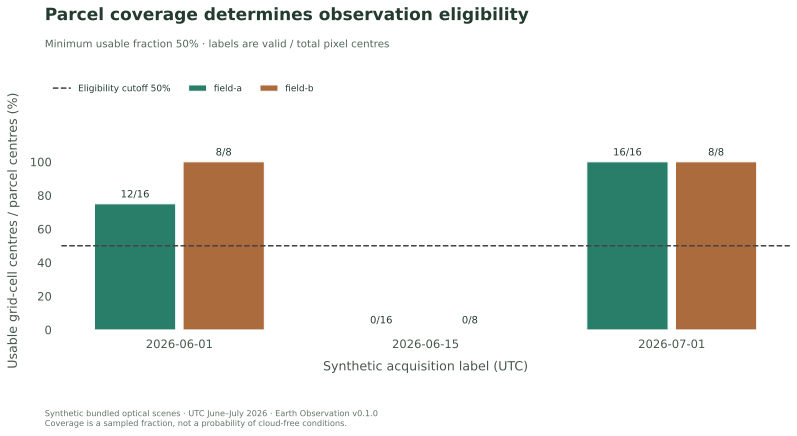

At **50%**, **4 of 6 observation rows** are eligible. **Rows retaining an index below cutoff: 0. Rows with no usable index: 2.** Bar labels are valid/total pixel-centre counts. The two parcels share scenes but cover different raster cells; treating a scene-level cloud label as parcel coverage would miss this distinction.

In [10]:
display(observations)
example.plot_coverage(observations, MIN_COVERAGE)
usable = int(observations.status.eq("ok").sum())
partial = int((observations.mean_index.notna() & observations.status.ne("ok")).sum())
missing = int(observations.mean_index.isna().sum())
prose(
    f"At **{MIN_COVERAGE:.0%}**, **{usable} of {len(observations)} observation rows** are eligible. **Rows retaining an index below cutoff: {partial}. Rows with no usable index: {missing}.** Bar labels are valid/total pixel-centre counts. The two parcels share scenes but cover different raster cells; treating a scene-level cloud label as parcel coverage would miss this distinction."
)

### A monthly row can conceal an unavailable acquisition

A monthly composite uses the pixelwise median over valid observations. In this fixture, the fully masked June scene contributes no valid samples. June still has a monthly mean based on the usable scene, and `scene_count=2` records that both scenes were considered. It does not mean two independent valid measurements supported every pixel.

The table retains the contributing scene ids and the count denominator. Monthly `observed_at` labels the first UTC day of the month, not an actual acquisition time. The charts retain the missing individual acquisition as a shaded time marker. Solid markers are eligible observations; hollow markers have a measured index but fail coverage. Dashed monthly lines show aggregation, not an observation through the cloudy date.

In [11]:
%%sql monthly <<
SELECT parcel_id,observed_at::DATE AS month_label,mean_index,valid_pixels,total_pixels,
 coverage_fraction,scene_count,scene_ids,status,delta_index,decline
FROM monthly_series ORDER BY parcel_id,observed_at;

In [12]:
%%sql diagnostics <<
SELECT parcel_id,count(*) AS observation_rows,count(mean_index) AS measured_rows,
 count(*) FILTER(WHERE status='ok') AS eligible_rows,count(delta_index) AS comparisons,
 count(*) FILTER(WHERE decline) AS declines
FROM selected_observations GROUP BY parcel_id ORDER BY parcel_id;

,parcel_id,month_label,mean_index,valid_pixels,total_pixels,coverage_fraction,scene_count,scene_ids,status,delta_index,decline
0,field-a,2026-06-01,6.000000e-01,12,16,0.75,2,"[""scene-0"", ""scene-1""]",ok,NaN,<NA>
1,field-a,2026-07-01,6.938894e-18,16,16,1.00,1,"[""scene-2""]",ok,-0.6,True
2,field-b,2026-06-01,6.000000e-01,8,8,1.00,2,"[""scene-0"", ""scene-1""]",ok,NaN,<NA>
3,field-b,2026-07-01,1.387779e-17,8,8,1.00,1,"[""scene-2""]",ok,-0.6,True


,parcel_id,observation_rows,measured_rows,eligible_rows,comparisons,declines
0,field-a,3,2,2,1,1
1,field-b,3,2,2,1,1


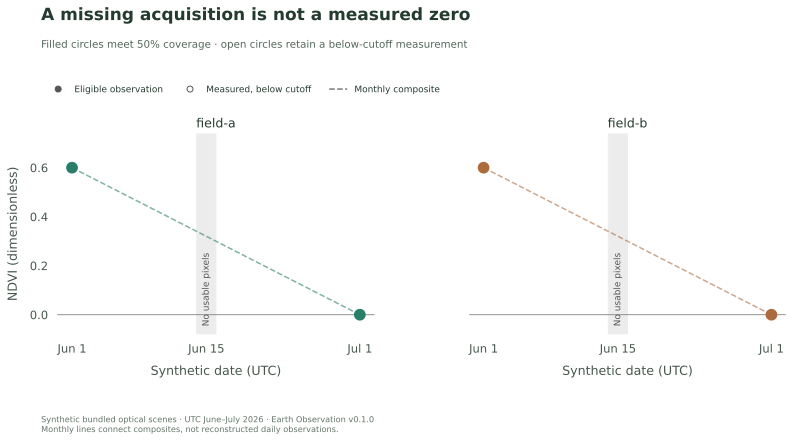

**Eligible temporal comparisons: 2. Decline flags at −0.3: 2.** Monthly aggregation returns **4 parcel-month rows** from **6 parcel-observation rows**. The July index is numerically near zero because its constructed NIR and red values are equal; the cloudy June acquisition is NULL. A coverage rule can remove a comparison without changing either measured endpoint. NDVI change alone does not identify a cause or establish crop stress.

6881

In [13]:
display(monthly)
display(diagnostics)
example.plot_months(observations, monthly, MIN_COVERAGE)
comparisons = int(diagnostics.comparisons.sum())
declines = int(diagnostics.declines.sum())
prose(
    f"**Eligible temporal comparisons: {comparisons}. Decline flags at −0.3: {declines}.** Monthly aggregation returns **{len(monthly)} parcel-month rows** from **{len(observations)} parcel-observation rows**. The July index is numerically near zero because its constructed NIR and red values are equal; the cloudy June acquisition is NULL. A coverage rule can remove a comparison without changing either measured endpoint. NDVI change alone does not identify a cause or establish crop stress."
)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "min_coverage": MIN_COVERAGE,
            "fingerprint": fingerprint,
            "reference": json.loads(reference.to_json(orient="records", date_format="iso")),
            "observations": json.loads(observations.to_json(orient="records", date_format="iso")),
            "monthly": json.loads(monthly.to_json(orient="records", date_format="iso")),
            "diagnostics": diagnostics.to_dict(orient="records"),
            "checks": checks.to_dict(orient="records"),
        },
        indent=2,
    )
)

### Experiment: require 90% usable coverage

Change only `MIN_COVERAGE` from **0.50 to 0.90**. Predict that field-a's partly observed June mean stays visible but loses eligibility, so its July value has no earlier eligible baseline. Field-b should retain its comparison. Compare the measured-input fingerprint, coverage bars, statuses, NULL change fields and decline counts. The raster data, mean values and fully cloudy rows must remain unchanged. Restore **0.50** afterwards.

The exercise shows sensitivity to an explicit analysis rule on fixed synthetic data. It is not evidence about any real location, classifier quality, agricultural outcome or suitable operational cutoff. For real imagery, retain source versions, calibration metadata, CRS, masks, date bounds and resource limits alongside the result; cloud coverage and temporal gaps are part of the result, not optional cleanup.

In [14]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-earth-observation](https://github.com/Query-farm/vgi-earth-observation)